# 2. Analyse et segmentation

Les résultats principaux du projet, avec leurs intervalles de confiance, la
validation du score d'intensité, la segmentation et son analyse de
sensibilité. Les figures sont aussi exportées dans `docs/images` pour le README.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats as sps

from dcca import config as cfg
from dcca.build import load_tables
from dcca.segments import SEGMENT_ORDER, segment_shares_by_variant
from dcca.stats import bootstrap_median, independence_test, share, share_table

FIG_DIR = Path("..") / "docs" / "images"
FIG_DIR.mkdir(parents=True, exist_ok=True)
NAVY, BLUE, SKY, GREY, ACCENT = "#0A2540", "#1E90FF", "#7FDBFF", "#B6C2CF", "#F28C6B"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "font.size": 10,
    }
)

t = load_tables()
r = t.respondents
consumers = r[r["consommateur"]]
b = consumers[consumers["sous_echantillon"] == "B"]


def fmt(s):
    return f"{s.value:.1%} [{s.low:.1%} ; {s.high:.1%}], base {s.base}"

## Les chiffres clés, avec leur précision

In [2]:
key = {
    "Consomment au moins un contenu (tous)": share(r["consommateur"]),
    "Passent par l'illégal (consommateurs)": share(consumers["illicite"]),
    "Au moins autant d'illégal que de légal": share(consumers["illicite_marque"]),
    "Paient chaque mois (consommateurs B)": share(b["payeur"]),
    "Abonnés SVOD dans le foyer (tous)": share(r["abonne_svod"]),
    "Utilisent un compte extérieur (tous)": share(r["compte_exterieur"]),
}
for label, s in key.items():
    print(f"{label:45s} {fmt(s)}")
m, lo, hi = bootstrap_median(b["depense_mensuelle"])
print(f"{'Dépense mensuelle médiane (B)':45s} {m:.0f} € [{lo:.0f} ; {hi:.0f}]")

Consomment au moins un contenu (tous)         91.4% [90.6% ; 92.2%], base 5041
Passent par l'illégal (consommateurs)         24.3% [23.1% ; 25.6%], base 4609
Au moins autant d'illégal que de légal        11.9% [11.0% ; 12.9%], base 4609
Paient chaque mois (consommateurs B)          66.6% [65.0% ; 68.2%], base 3227
Abonnés SVOD dans le foyer (tous)             55.0% [53.6% ; 56.3%], base 5041
Utilisent un compte extérieur (tous)          26.7% [25.5% ; 28.0%], base 5041
Dépense mensuelle médiane (B)                 12 € [10 ; 13]


Sur l'échantillon brut, 91,4 % des internautes consomment au moins un contenu
en ligne. L'Arcom publie 91 % pour 2024 après redressement : l'absence de
poids ne déforme pas ce chiffre.

## L'âge, premier facteur de l'illicite

In [3]:
by_age = share_table(consumers, "illicite", "tranche_age", cfg.AGE_GROUP_ORDER)
by_age

,tranche_age,part,ic_bas,ic_haut,base,fiable
0,15-24 ans,0.424936,0.390825,0.459778,786,True
1,25-34 ans,0.399103,0.362672,0.436686,669,True
2,35-49 ans,0.240478,0.218350,0.264091,1339,True
3,50-64 ans,0.123157,0.105430,0.143386,1153,True
4,65 ans et plus,0.084592,0.065717,0.108261,662,True


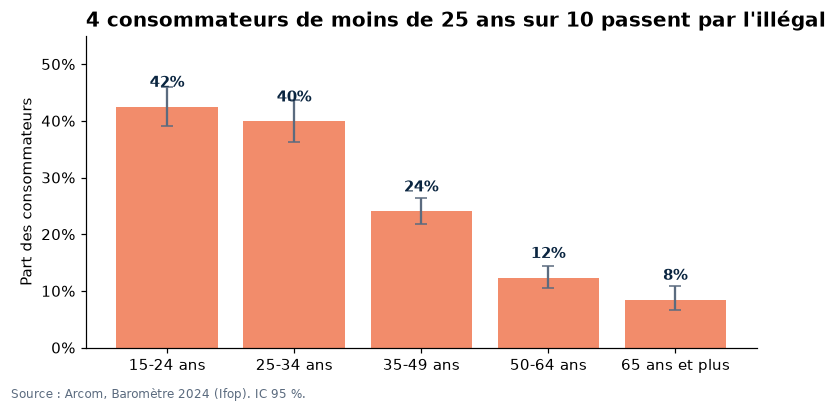

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(by_age["tranche_age"], by_age["part"], color=ACCENT)
ax.errorbar(
    by_age["tranche_age"],
    by_age["part"],
    yerr=[by_age["part"] - by_age["ic_bas"], by_age["ic_haut"] - by_age["part"]],
    fmt="none",
    ecolor="#5B6B7F",
    capsize=4,
)
for x, p in zip(by_age["tranche_age"], by_age["part"], strict=True):
    ax.text(x, p + 0.035, f"{p:.0%}", ha="center", fontweight="bold", color=NAVY)
ax.set_ylim(0, 0.55)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("4 consommateurs de moins de 25 ans sur 10 passent par l'illégal")
ax.set_ylabel("Part des consommateurs")
fig.text(
    0.01, -0.02, "Source : Arcom, Baromètre 2024 (Ifop). IC 95 %.", fontsize=8, color="#5B6B7F"
)
fig.tight_layout()
fig.savefig(FIG_DIR / "illicite_par_age.png", bbox_inches="tight")

L'âge pèse bien plus que la géographie. Je compare la force du lien avec le V
de Cramér (0 = aucun lien, 1 = lien parfait) :

In [5]:
pd.DataFrame(
    {
        var: {"V de Cramér": round(independence_test(consumers, "illicite", var).cramers_v, 3)}
        for var in ["tranche_age", "region", "agglomeration", "sexe", "csp"]
    }
).T.sort_values("V de Cramér", ascending=False)

,V de Cramér
tranche_age,0.298
csp,0.241
agglomeration,0.104
region,0.079
sexe,0.070


## Le score d'intensité tient-il la route ?

Le score (50 % étendue, 50 % régularité) n'utilise ni la dépense ni les
abonnements. S'il mesure bien l'engagement, il doit être corrélé positivement
avec les deux.

In [6]:
rho_spend = sps.spearmanr(b["score_intensite"], b["depense_mensuelle"], nan_policy="omit")
rho_subs = sps.spearmanr(consumers["score_intensite"], consumers["n_abonnements"])
print(f"Spearman score / dépense : {rho_spend.statistic:.2f} (p = {rho_spend.pvalue:.1e})")
print(f"Spearman score / nombre d'abonnements : {rho_subs.statistic:.2f}")

Spearman score / dépense : 0.37 (p = 9.9e-107)
Spearman score / nombre d'abonnements : 0.35


In [7]:
quart = pd.qcut(b["score_intensite"], 4, labels=["Q1 (faible)", "Q2", "Q3", "Q4 (fort)"])
b.groupby(quart, observed=True)["depense_mensuelle"].agg(["median", "mean", "size"]).round(1)

,median,mean,size
score_intensite,,,
Q1 (faible),0.0,17.8,860
Q2,10.0,21.3,929
Q3,15.0,28.6,711
Q4 (fort),30.0,39.4,733


La dépense médiane monte avec chaque quartile du score : le score capte bien
l'engagement, sans être un doublon de la dépense (corrélation modérée).

## Segmentation

In [8]:
seg = pd.DataFrame(
    {
        s: {
            "part": share(consumers["segment"] == s).value,
            "ic_bas": share(consumers["segment"] == s).low,
            "ic_haut": share(consumers["segment"] == s).high,
            "effectif": int((consumers["segment"] == s).sum()),
        }
        for s in SEGMENT_ORDER
    }
).T
seg

,part,ic_bas,ic_haut,effectif
Abonnés légaux,0.519852,0.505418,0.534253,2396.0
Hybrides,0.197223,0.185990,0.208960,909.0
Abonnés par procuration,0.053157,0.047044,0.060014,245.0
Gratuit légal,0.183771,0.172855,0.195214,847.0
Illicites sans abonnement,0.045997,0.040318,0.052432,212.0


In [9]:
paying_illicit = (consumers["segment"] == "Hybrides").sum() / consumers["illicite"].sum()
print(f"Part des consommateurs illicites qui paient au moins un abonnement : {paying_illicit:.1%}")

Part des consommateurs illicites qui paient au moins un abonnement : 81.1%


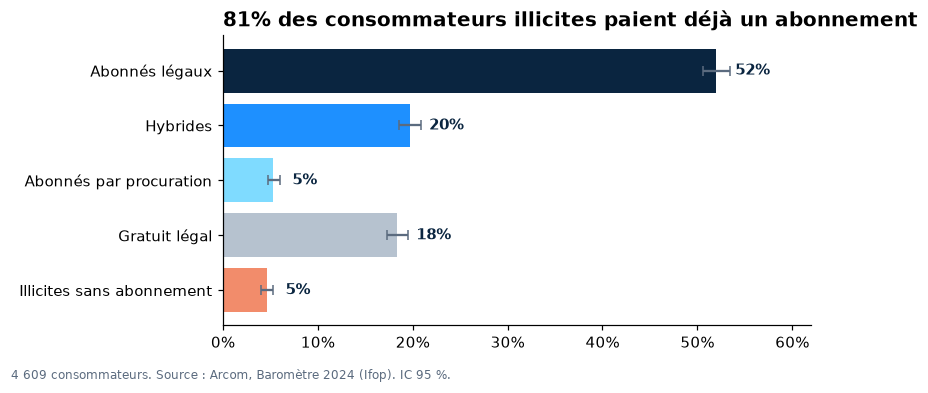

In [10]:
colors = [NAVY, BLUE, SKY, GREY, ACCENT]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(seg.index, seg["part"].astype(float), color=colors)
ax.errorbar(
    seg["part"].astype(float),
    seg.index,
    xerr=[
        (seg["part"] - seg["ic_bas"]).astype(float),
        (seg["ic_haut"] - seg["part"]).astype(float),
    ],
    fmt="none",
    ecolor="#5B6B7F",
    capsize=3,
)
for y, p in zip(seg.index, seg["part"].astype(float), strict=True):
    ax.text(p + 0.02, y, f"{p:.0%}", va="center", fontweight="bold", color=NAVY)
ax.invert_yaxis()
ax.set_xlim(0, 0.62)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title(f"{paying_illicit:.0%} des consommateurs illicites paient déjà un abonnement")
fig.text(
    0.01,
    -0.03,
    "4 609 consommateurs. Source : Arcom, Baromètre 2024 (Ifop). IC 95 %.",
    fontsize=8,
    color="#5B6B7F",
)
fig.tight_layout()
fig.savefig(FIG_DIR / "segments.png", bbox_inches="tight")

### Le lien avec l'âge

In [11]:
test = independence_test(consumers, "segment", "tranche_age")
print(
    f"khi-deux = {test.chi2:.0f}, ddl = {test.dof}, p = {test.p_value:.1e}, V de Cramér = {test.cramers_v:.2f}"
)
pd.crosstab(consumers["tranche_age"], consumers["segment"], normalize="index")[SEGMENT_ORDER].round(
    3
)

khi-deux = 777, ddl = 16, p = 4.9e-155, V de Cramér = 0.21


segment,Abonnés légaux,Hybrides,Abonnés par procuration,Gratuit légal,Illicites sans abonnement
tranche_age,,,,,
15-24 ans,0.492,0.366,0.039,0.043,0.059
25-34 ans,0.502,0.344,0.049,0.049,0.055
35-49 ans,0.566,0.193,0.046,0.148,0.048
50-64 ans,0.546,0.087,0.070,0.260,0.036
65 ans et plus,0.431,0.050,0.059,0.426,0.035


### Sensibilité aux règles

Les seuils sont fixés à la main. Je teste deux variantes : une définition
stricte de l'illicite (au moins autant d'illégal que de légal) et une
définition large de l'abonné (y compris « autre abonnement »).

In [12]:
variants = segment_shares_by_variant(r)
variants["Part des illicites qui paient"] = variants["Hybrides"] / (
    variants["Hybrides"] + variants["Illicites sans abonnement"]
)
variants.round(3)

segment,Abonnés légaux,Hybrides,Abonnés par procuration,Gratuit légal,Illicites sans abonnement,Part des illicites qui paient
Définition retenue,0.520,0.197,0.053,0.184,0.046,0.811
Illicite = au moins autant d'illégal que de légal,0.622,0.095,0.063,0.195,0.025,0.795
Abonné = y compris « autre abonnement »,0.524,0.199,0.052,0.181,0.045,0.816


Avec la définition stricte, les hybrides passent de 20 % à 9 % : la plupart
ne piratent que de temps en temps. Mais la part des illicites qui paient un
abonnement reste autour de 80 % : c'est le résultat robuste du projet.

## Abonnements partagés

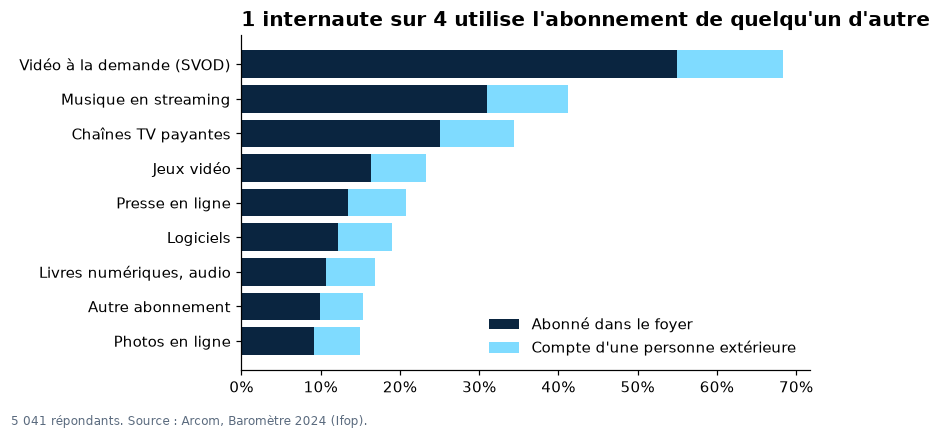

In [13]:
s = t.subscriptions
access = s.groupby("abonnement")[["abonne_foyer", "compte_exterieur"]].mean()
access = access.sort_values("abonne_foyer")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(access.index, access["abonne_foyer"], color=NAVY, label="Abonné dans le foyer")
ax.barh(
    access.index,
    access["compte_exterieur"],
    left=access["abonne_foyer"],
    color=SKY,
    label="Compte d'une personne extérieure",
)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, loc="lower right")
shared = share(r["compte_exterieur"]).value
ax.set_title(f"1 internaute sur {round(1 / shared)} utilise l'abonnement de quelqu'un d'autre")
fig.text(
    0.01,
    -0.03,
    "5 041 répondants. Source : Arcom, Baromètre 2024 (Ifop).",
    fontsize=8,
    color="#5B6B7F",
)
fig.tight_layout()
fig.savefig(FIG_DIR / "abonnements.png", bbox_inches="tight")

In [14]:
users = s[s["compte_exterieur"]].groupby("id")[list(cfg.SHARED_CODE_ORIGIN_COLUMNS.values())].any()
users.mean().rename(
    index=dict(
        zip(
            cfg.SHARED_CODE_ORIGIN_COLUMNS.values(),
            cfg.SHARED_CODE_ORIGIN_LABELS.values(),
            strict=True,
        )
    )
).round(3)

Famille                       0.805
Amis                          0.455
Codes trouvés sur Internet    0.178
Autres personnes              0.110
dtype: float64

## Ce qui fait payer : le prix

Les raisons de ne pas passer par le légal (consommateurs illicites du
sous-échantillon B, plusieurs réponses possibles) :

In [15]:
reasons = t.reasons.groupby("raison")["citee"].mean().sort_values(ascending=False)
reasons.head(8).round(3)

raison
Abonnements trop chers                 0.442
Prix à l'unité trop élevé              0.373
Pourquoi payer ce qui est gratuit ?    0.206
Habitude du gratuit                    0.174
Œuvre introuvable en légal             0.171
Offre légale trop limitée              0.159
Peur de donner sa carte bancaire       0.136
Nouveautés pas assez rapides           0.133
Name: citee, dtype: float64